In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import datetime
from matplotlib.dates import YearLocator, MonthLocator, DateFormatter
from scipy.signal import find_peaks
from scipy import stats

In [2]:
# Reading .csv file and displaying columns and column names

df = pd.read_csv('Cowid-covid-data.csv', parse_dates=True)
#print(df.head())
#print(df.columns)

In [3]:
# Averaging cases per week
df['New_cases_averaged'] = df.new_cases_smoothed.rolling(7).mean() 

# Selecting information relevant to india
df2 = df[df['location'] == 'Spain']

# Creating new database containing all values for selected country
df2.to_csv('Modified.csv',index=False)
df2 = pd.read_csv('Modified.csv') 

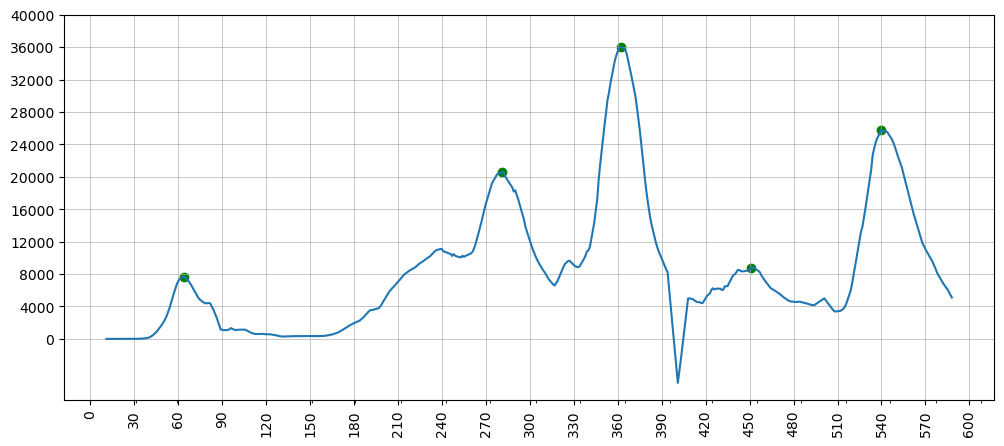

In [4]:
# Find local peaks according to given conditions
peaks,_ = find_peaks(df2.New_cases_averaged, distance=80, height=4000)
A = peaks
# Plot figure 
fig, ax=plt.subplots(1, 1, figsize=(12, 5))
years = YearLocator()   # every year
months = MonthLocator()  # every month
#years_fmt = DateFormatter('%m-%Y') #This is a format
plt.plot(df2.New_cases_averaged)
plt.scatter(peaks, df2.New_cases_averaged[peaks], color='g')
ax.xaxis.set_major_locator(months)
#ax.xaxis.set_major_formatter(years_fmt)
ax.xaxis.set_minor_locator(months)
plt.xticks(rotation = 'vertical')
plt.yticks(np.arange(0, 42000, 4000))
plt.xticks(np.arange(0, 630, 30))
plt.grid(linewidth = 0.5)
plt.show()

In [5]:
# Automating the definition of thresholds via a function
P = np.zeros(len(A))
T = np.zeros(len(A))
W = np.array(df2.New_cases_averaged)
def get_peak(arr, threshold):           # Function to output the x-location of specified threshold
    x = np.argsort(np.abs(W - threshold))[0:2]
    x1, x2 = np.min(x), np.max(x)
    return x1, x2
for i in range(len(peaks)):
    x = np.array(df2.New_cases_averaged[A[i]]) 
    P[i] = x
    t = 0.5*x                           # Threshold level specified
    T[i] = t
    arr = np.array(df2.New_cases_averaged)
    x1, x2 = get_peak(W, t)
    print('\nLeft hand side threshold for peak {a}:'.format(a = i+1),x1)
    print('Right hand side threshold for peak {a}:'.format(a = i+1),x2)


Left hand side threshold for peak 1: 197
Right hand side threshold for peak 1: 506

Left hand side threshold for peak 2: 249
Right hand side threshold for peak 2: 338

Left hand side threshold for peak 3: 272
Right hand side threshold for peak 3: 289

Left hand side threshold for peak 4: 80
Right hand side threshold for peak 4: 496

Left hand side threshold for peak 5: 265
Right hand side threshold for peak 5: 566



The x-value of the point to the left of peak satisfying threshold condition of peak number 1 is 50
The x-value of the point to the right of peak satisfying threshold condition of peak number 1 is 80

The x-value of the point to the left of peak satisfying threshold condition of peak number 2 is 270
The x-value of the point to the right of peak satisfying threshold condition of peak number 2 is 295

The x-value of the point to the left of peak satisfying threshold condition of peak number 3 is 350
The x-value of the point to the right of peak satisfying threshold condition of peak number 3 is 380

The x-value of the point to the left of peak satisfying threshold condition of peak number 4 is 440
The x-value of the point to the right of peak satisfying threshold condition of peak number 4 is 460

The x-value of the point to the left of peak satisfying threshold condition of peak number 5 is 530
The x-value of the point to the right of peak satisfying threshold condition of peak number 5

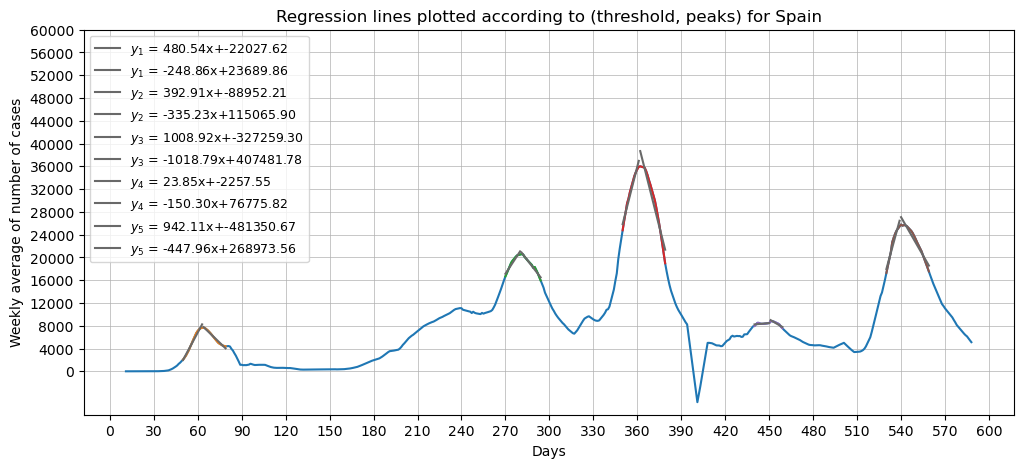

In [6]:
plt.figure(figsize = (12, 5))
plt.plot(df2.New_cases_averaged)
X1 = [50, 270, 350, 440, 530] # Specified left Threshold of each peak
X2 = [80, 295, 380, 460, 560] # Specified right Threshold of each peak

for i in range(len(peaks)):
    x1, x2 =  X1[i], X2[i]
    plt.plot(np.arange(x1, x2, 1), arr[x1:x2])
    print("\nThe x-value of the point to the left of peak satisfying threshold condition of peak number {a} is".format(a = i+1), x1)
    print("The x-value of the point to the right of peak satisfying threshold condition of peak number {a} is".format(a = i+1), x2)    
    slope_l, intercept_l, _, _, _ = stats.linregress(np.arange(x1, peaks[i], 1), arr[x1:peaks[i]])
    x_arr = np.arange(x1, peaks[i], 1)
    y_arr = (slope_l * x_arr) + intercept_l
    plt.plot(x_arr, y_arr, color='dimgrey', label = '$y_{:.0f}$ = {:.2f}x+{:.2f}'.format(i+1, slope_l,intercept_l))
    slope_r, intercept_r, _, _, _ = stats.linregress(np.arange(peaks[i], x2, 1), arr[peaks[i]:x2])
    x_arr = np.arange(peaks[i], x2, 1)
    y_arr = (slope_r * x_arr) + intercept_r
    plt.plot(x_arr, y_arr, color='dimgrey', label = '$y_{:.0f}$ = {:.2f}x+{:.2f}'.format(i+1, slope_r,intercept_r))

plt.title('Regression lines plotted according to (threshold, peaks) for Spain')
plt.xlabel('Days')
plt.yticks(np.arange(0, 62000, 4000))
plt.ylabel('Weekly average of number of cases')
plt.xticks(np.arange(0, 630, 30))
plt.grid(linewidth = 0.5)
plt.legend(fontsize=9)
plt.show()